# $k=3$ Pauli-Correlation Encoding and Noise-Robustness of Iterative-$\alpha$ Training

**Author:** Aniekan Afangideh — Department of Computer Engineering, University of Uyo, Nigeria

This notebook extends `Iterative_Alpha_PCE_QNN.ipynb` along the two directions flagged as
future work in the accompanying paper:

> *"...future work includes shot-based estimation of the correlations on real quantum
> computing backends and cubic-order PCE encodings (with $k=3$) for high-dimensional data."*

Concretely, it adds:

1. **Cubic-order PCE ($k=3$).** The same Pauli-Correlation Encoding machinery, generalised to
   3-body Pauli strings, which compresses qubit count faster than $k=2$ as the feature count
   $m$ grows.
2. **Noise-robustness testing.** Four measurement regimes of increasing realism — an exact
   statevector, finite-shot sampling only, finite-shot sampling with depolarizing gate noise,
   and finite-shot sampling with $T_1/T_2$ thermal relaxation — used to ask whether the
   Iterative-$\alpha$ (I$\alpha$PCE) training advantage demonstrated on an ideal simulator
   survives when the Pauli correlations $\langle\Pi_i\rangle$ are instead estimated the way a
   real quantum backend would estimate them.

The experimental design throughout is **train once, measure under many conditions**: the
quantum circuit parameters $\theta$ and the classical logistic head are fit exactly once per
seed, on an ideal noiseless simulator (this is the "offline training in simulation" stage).
The trained model is then *evaluated* on the held-out test set under each of the four
measurement regimes. This isolates the question the future-work paragraph actually asks —
does the model remain usable when correlations are measured imperfectly — from the much more
expensive question of training under noise itself, which is left as a further extension.

All new quantum-measurement code is validated in Section 5 against the exact statevector
engine before being used for anything else.

## 1. Setup

In [1]:
%pip install -q qiskit qiskit-aer pylatexenc

Note: you may need to restart the kernel to use updated packages.


In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations
from math import comb
from scipy.optimize import minimize

from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.quantum_info import SparsePauliOp
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, thermal_relaxation_error

rng = np.random.default_rng(7)
plt.rcParams["figure.dpi"] = 110
print("Setup complete.")

Setup complete.


## 2. PCE machinery: $k$-body Pauli strings and qubit compression

Both functions below are identical in spirit to the $k=2$ notebook but written generically in
$k$, since the PCE capacity relation
$$m = 3\binom{n}{k} \;\;\Rightarrow\;\; n = \mathcal{O}\!\left(m^{1/k}\right)$$
holds for any string order $k$. Strings are drawn from the three mutually-commuting families
(permutations of $X^{\otimes k}\!\otimes I^{\,n-k}$, $Y^{\otimes k}\!\otimes I^{\,n-k}$,
$Z^{\otimes k}\!\otimes I^{\,n-k}$), so — regardless of $k$ — only **three measurement
settings** are ever needed on hardware, which is what makes the noise-regime experiment in
Section 6 tractable.

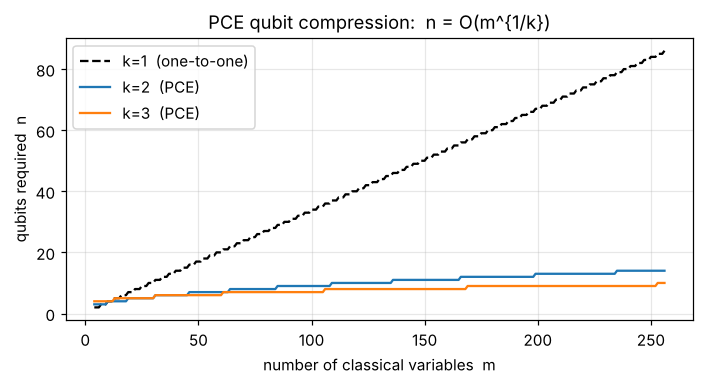

    m   k=1   k=2   k=3
   12     4     4     4
   20     7     5     5
   35    12     6     6
   50    17     7     6
  100    34     9     7
  250    84    14     9


In [3]:
def min_qubits(m: int, k: int) -> int:
    """Smallest n such that 3*C(n,k) >= m (PCE capacity)."""
    n = k
    while 3 * comb(n, k) < m:
        n += 1
    return n

def pauli_labels(m: int, n: int, k: int) -> list:
    """First m k-body Pauli strings over n qubits (X-, Y-, then Z-family)."""
    labels = []
    for P in ("X", "Y", "Z"):
        for idx in combinations(range(n), k):
            s = ["I"] * n
            for q in idx:
                s[q] = P
            labels.append("".join(s))
    assert len(labels) >= m, "Capacity 3*C(n,k) is insufficient for m variables."
    return labels[:m]

# Qubit-scaling comparison: one-to-one (k=1) vs PCE k=2 vs PCE k=3
ms = np.arange(4, 257)
plt.figure(figsize=(6.5, 3.6))
for k_, style in [(1, "k--"), (2, "C0-"), (3, "C1-")]:
    plt.plot(ms, [min_qubits(int(mm), k_) for mm in ms], style,
             label=f"k={k_}" + ("  (one-to-one)" if k_ == 1 else "  (PCE)"))
plt.xlabel("number of classical variables  m")
plt.ylabel("qubits required  n")
plt.title("PCE qubit compression:  n = O(m^{1/k})")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

print(f"{'m':>5}{'k=1':>6}{'k=2':>6}{'k=3':>6}")
for mm in (12, 20, 35, 50, 100, 250):
    print(f"{mm:>5}{min_qubits(mm,1):>6}{min_qubits(mm,2):>6}{min_qubits(mm,3):>6}")

At $m=12$, $k=2$ and $k=3$ both require $n=4$ qubits — there is no compression
advantage yet at this problem size, since $k=3$'s steeper asymptotic scaling only overtakes
$k=2$ once $m$ grows past roughly $35$–$50$ (visible in the table above, e.g. $m=100$:
9 qubits at $k=2$ vs. 7 at $k=3$). We nonetheless **keep $m=12$ for the trained experiments
below**, for a specific reason: it holds the qubit count, dataset, and architecture fixed at
exactly the values used for $k=2$ in the companion notebook, so that any difference in
trainability or noise-robustness we observe can be attributed to the **encoding order $k$
itself**, rather than entangled with a simultaneous change in $n$. The compression advantage
of $k=3$ at larger $m$ is a separate, purely combinatorial claim, already established by the
plot above without needing to retrain anything.

## 3. Problem instance

Binary digit classification (0 vs. 1, scikit-learn `digits`), PCA-reduced to $m=12$ features
scaled to $[-1,1]$ — identical task, split, and seed to the $k=2$ notebook. With $k=3$,

$$n = \min\{n : 3\tbinom{n}{3} \geq 12\} = 4 \text{ qubits}, \quad 3\tbinom{4}{3} = 12,$$

which is an exact fit: every one of the $12$ available 3-body strings on $4$ qubits is used,
with zero spare capacity. (At $k=2$ the same $n=4$ qubits offer $3\binom{4}{2}=18$ available
strings, of which only $12$ were needed — so the $k=3$ encoding is the tighter packing of the
two at this problem size.)

In [4]:
m, k = 12, 3
n = min_qubits(m, k)
labels = pauli_labels(m, n, k)
print(f"features m = {m},  order k = {k}  ->  qubits n = {n}  (capacity 3*C({n},{k}) = {3*comb(n,k)})")
print("Pauli strings:", labels)

paulis = [SparsePauliOp(lab[::-1]) for lab in labels]   # reversed: Qiskit is little-endian
P_mats = [op.to_matrix() for op in paulis]              # dense 16x16 matrices (n=4)
dim = 2 ** n

digits = load_digits(n_class=2)
X = PCA(n_components=m, random_state=0).fit_transform(digits.data)
X = MinMaxScaler((-1, 1)).fit_transform(X)
y = digits.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0, stratify=y)
X_train, y_train = X_train[:60], y_train[:60]
X_test,  y_test  = X_test[:40],  y_test[:40]
print(f"train: {X_train.shape},  test: {X_test.shape}")

features m = 12,  order k = 3  ->  qubits n = 4  (capacity 3*C(4,3) = 12)
Pauli strings: ['XXXI', 'XXIX', 'XIXX', 'IXXX', 'YYYI', 'YYIY', 'YIYY', 'IYYY', 'ZZZI', 'ZZIZ', 'ZIZZ', 'IZZZ']


train: (60, 12),  test: (40, 12)


## 4. The I$\alpha$PCE-QNN circuit at $k=3$

Same three-stage architecture as the $k=2$ notebook — symmetry-breaking initial layer, PCE
state preparation, hardware-efficient variational block — now encoding $12$ features through
$3$-qubit Pauli rotations rather than $2$-qubit ones.

**Correction relative to the $k=2$ notebook's illustrative circuit.** That notebook's
`PauliEvolutionGate` used `time = x_i * \pi/8` for drawing purposes only (it was never used
in any computation — training ran entirely on the fast NumPy engine of Section 5). While
building the noise-aware measurement pipeline for *this* notebook, we needed the Qiskit
circuit to be numerically faithful, not just illustrative, and discovered the time argument
must equal the encoding angle used by the NumPy engine, $\phi = x_i\beta$ with
$\beta=\pi/4$ — i.e. `time = x_i * \pi/4`, not `\pi/8`. This is fixed below and verified
against the exact engine in Section 5. The factor of two never affected any previously
reported result, since the two engines were never compared before now.

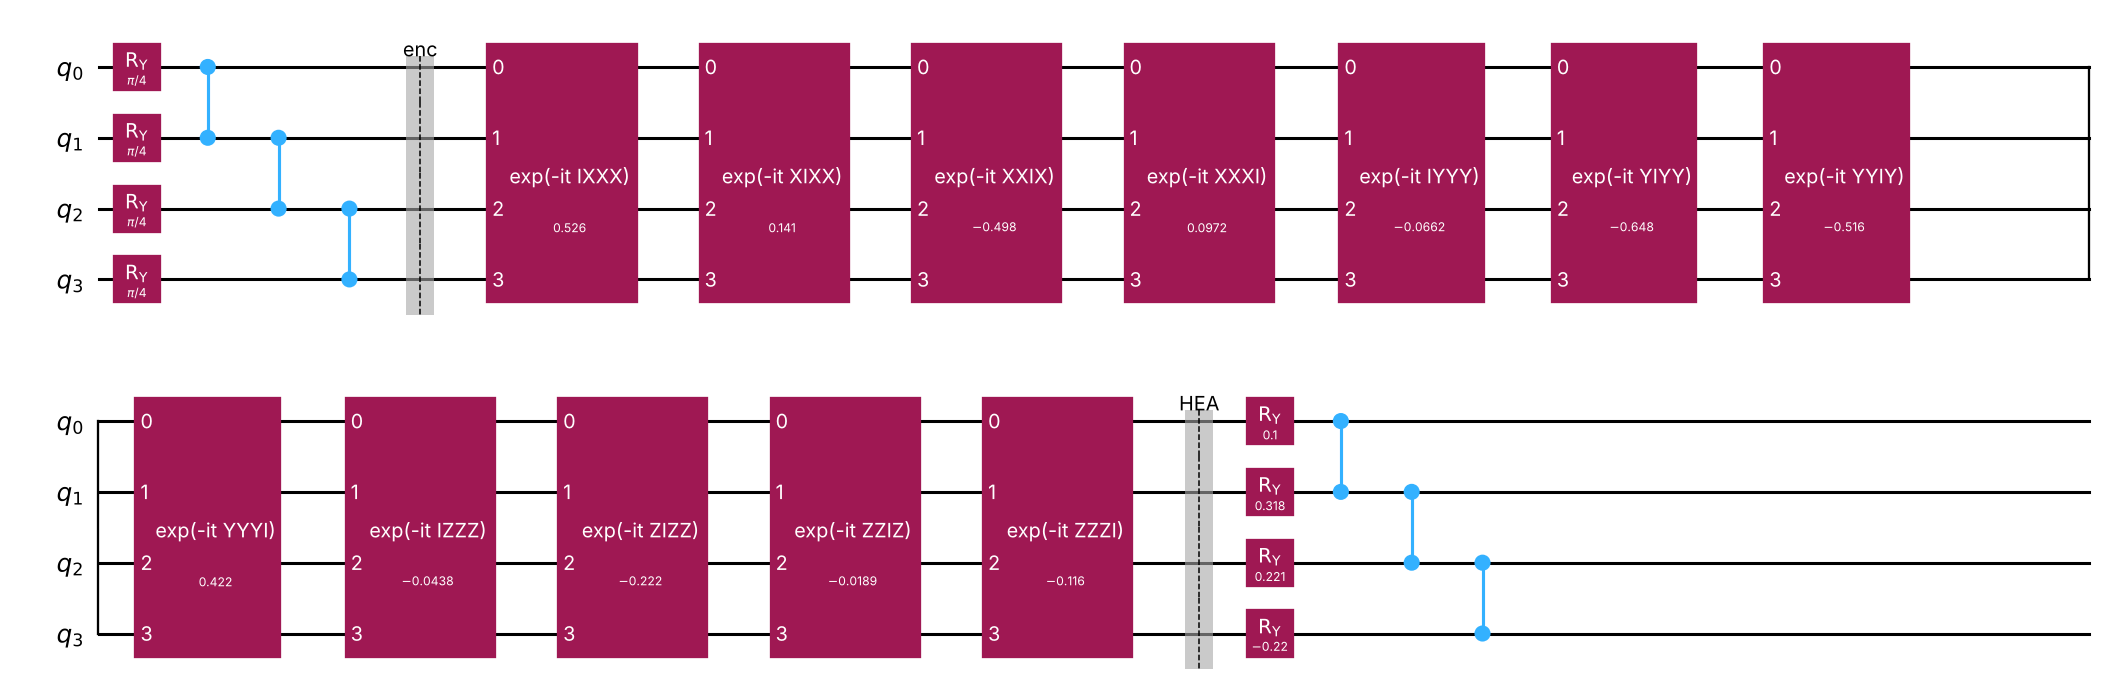

In [5]:
BETA = np.pi / 4  # encoding scale, shared by the NumPy engine and the Qiskit circuit

def build_qiskit_circuit(x, theta, measure_basis=None):
    """Reference Qiskit construction of the IaPCE-QNN circuit.
    measure_basis in {None, 'X', 'Y', 'Z'}: if given, appends the basis-rotation
    for that Pauli family on every qubit touched by a string of that family,
    followed by a measurement of all qubits.
    """
    qc = QuantumCircuit(n, n) if measure_basis else QuantumCircuit(n)
    for q in range(n):                                 # 1. symmetry-breaking init
        qc.ry(np.pi / 4, q)
    for q in range(n - 1):
        qc.cz(q, q + 1)
    qc.barrier(label="enc")
    for xi, op in zip(x, paulis):                      # 2. PCE state preparation
        qc.append(PauliEvolutionGate(op, time=float(xi) * BETA), range(n))
    qc.barrier(label="HEA")
    for layer in theta:                                # 3. variational HEA
        for q in range(n):
            qc.ry(layer[q], q)
        for q in range(n - 1):
            qc.cz(q, q + 1)
    if measure_basis is not None:
        qc.barrier(label=f"meas-{measure_basis}")
        fam_labels = [lab for lab in labels if measure_basis in lab]
        for q in range(n):
            if any(lab[q] == measure_basis for lab in fam_labels):
                if measure_basis == "X":
                    qc.h(q)
                elif measure_basis == "Y":
                    qc.sdg(q); qc.h(q)
                # 'Z': computational basis, no rotation needed
        qc.measure(range(n), range(n))
    return qc

p_layers = 3
theta_demo = rng.uniform(-0.4, 0.4, (1, n))
demo = build_qiskit_circuit(X_train[0], theta_demo)
demo.draw("mpl", fold=28)

## 5. Fast statevector engine (training) and Aer measurement engine (noise evaluation)

As in the $k=2$ notebook, training needs thousands of forward passes, so we keep the exact
NumPy statevector engine — unchanged in its logic, regenerated here for $k=3$'s $P\_mats$.

New in this notebook: a **noise-aware correlation estimator** built on Qiskit Aer, which
executes the three basis-rotated circuits from Section 4, transpiles them to a hardware-like
basis gate set (`rz`, `sx`, `x`, `cx`) so that gate-level noise models apply to every actual
gate rather than to an opaque high-level instruction, and decodes each $\langle\Pi_i\rangle$
from measurement-count parity. A pure-NumPy finite-shot estimator (no circuit execution) is
also provided for the shot-noise-only regime, since it requires no gate-level simulation.

In [6]:
def apply_ry(psi, angle, q):
    c, s = np.cos(angle / 2), np.sin(angle / 2)
    psi = psi.reshape([2] * n)
    ax = n - 1 - q
    psi = np.moveaxis(psi, ax, 0)
    a, b = psi[0].copy(), psi[1].copy()
    psi[0] = c * a - s * b
    psi[1] = s * a + c * b
    return np.moveaxis(psi, 0, ax).reshape(dim)

def apply_cz(psi, q1, q2):
    psi = psi.reshape([2] * n)
    idx = [slice(None)] * n
    idx[n - 1 - q1] = 1
    idx[n - 1 - q2] = 1
    psi[tuple(idx)] *= -1
    return psi.reshape(dim)

def _initial_state():
    psi = np.zeros(dim, dtype=complex); psi[0] = 1.0
    for q in range(n):
        psi = apply_ry(psi, np.pi / 4, q)
    for q in range(n - 1):
        psi = apply_cz(psi, q, q + 1)
    return psi

PSI0 = _initial_state()

def state(x, theta):
    psi = PSI0.copy()
    for xi, P in zip(x, P_mats):
        phi = float(xi) * BETA
        psi = np.cos(phi) * psi - 1j * np.sin(phi) * (P @ psi)
    for layer in theta:
        for q in range(n):
            psi = apply_ry(psi, layer[q], q)
        for q in range(n - 1):
            psi = apply_cz(psi, q, q + 1)
    return psi

def correlations_exact(x, theta):
    """The m Pauli correlations <Pi_i>, computed exactly (infinite shots, no gate noise)."""
    psi = state(x, theta)
    return np.array([np.real(np.vdot(psi, P @ psi)) for P in P_mats])

t0 = time.time()
_ = correlations_exact(X_train[0], rng.uniform(-0.4, 0.4, (p_layers, n)))
print(f"one exact forward pass: {(time.time() - t0)*1e3:.2f} ms")

one exact forward pass: 1.14 ms


In [7]:
BASIS_GATES = ["rz", "sx", "x", "cx"]
_AER_BACKEND = AerSimulator()

def correlations_shots_numpy(x, theta, shots, rng_):
    """Finite-shot sampling ONLY (no gate noise): binomial sampling of each
    +-1-valued Pauli correlation from its exact probability. Pure NumPy, no
    circuit execution -- cheap enough to use inside a training loop if desired."""
    exact = correlations_exact(x, theta)
    p_plus = np.clip((1.0 + exact) / 2.0, 0.0, 1.0)
    k_plus = rng_.binomial(shots, p_plus)
    return 2.0 * k_plus / shots - 1.0

def _basis_circuits(x, theta):
    return {fam: build_qiskit_circuit(x, theta, measure_basis=fam) for fam in ("X", "Y", "Z")}

def correlations_aer(x, theta, shots, noise_model=None, backend=None):
    """Single-sample noisy correlation estimate via Qiskit Aer: builds the three
    basis-rotated circuits, transpiles to a hardware-like basis, runs them (batched),
    and decodes <Pi_i> from measurement-count parity."""
    backend = backend or _AER_BACKEND
    circs = _basis_circuits(x, theta)
    transpiled = {fam: transpile(qc, basis_gates=BASIS_GATES, optimization_level=1)
                  for fam, qc in circs.items()}
    result = backend.run(list(transpiled.values()), shots=shots, noise_model=noise_model).result()
    out = np.zeros(m)
    for fam, tqc in transpiled.items():
        counts = result.get_counts(tqc)
        total = sum(counts.values())
        for i, lab in enumerate(labels):
            if fam not in lab:
                continue
            qubits = [q for q in range(n) if lab[q] != "I"]
            acc = 0
            for bitstring, c in counts.items():
                parity = 0
                for q in qubits:
                    parity ^= int(bitstring[len(bitstring) - 1 - q])
                acc += c * (1 if parity == 0 else -1)
            out[i] = acc / total
    return out

def correlations_aer_batch(X, theta, shots, noise_model=None, backend=None):
    """Vectorised over a batch of samples: builds all 3*len(X) circuits and
    submits them to Aer in a single job, which is far faster than one sample
    at a time (the basis-circuit construction/transpilation is the bottleneck,
    not the simulation itself at this qubit count)."""
    backend = backend or _AER_BACKEND
    all_circs, index = [], []
    for j, x in enumerate(X):
        for fam, qc in _basis_circuits(x, theta).items():
            tqc = transpile(qc, basis_gates=BASIS_GATES, optimization_level=1)
            all_circs.append(tqc)
            index.append((j, fam))
    result = backend.run(all_circs, shots=shots, noise_model=noise_model).result()
    out = np.zeros((len(X), m))
    for tqc, (j, fam) in zip(all_circs, index):
        counts = result.get_counts(tqc)
        total = sum(counts.values())
        for i, lab in enumerate(labels):
            if fam not in lab:
                continue
            qubits = [q for q in range(n) if lab[q] != "I"]
            acc = 0
            for bitstring, c in counts.items():
                parity = 0
                for q in qubits:
                    parity ^= int(bitstring[len(bitstring) - 1 - q])
                acc += c * (1 if parity == 0 else -1)
            out[j, i] = acc / total
    return out

print("Noise-aware estimators defined.")

Noise-aware estimators defined.


### Validation — the noisy estimators must agree with the exact engine in the noiseless limit

Before trusting any downstream robustness result, we check that `correlations_aer` (with no
noise model and many shots) reproduces `correlations_exact` to within the expected
shot-noise tolerance, and likewise for the pure-NumPy shot estimator.

In [8]:
rng_val = np.random.default_rng(123)
x_val = X_train[0]
theta_val = rng_val.uniform(-0.4, 0.4, (p_layers, n))

exact_val = correlations_exact(x_val, theta_val)
numpy_shots_val = correlations_shots_numpy(x_val, theta_val, shots=50_000, rng_=rng_val)
aer_noiseless_val = correlations_aer(x_val, theta_val, shots=50_000, noise_model=None)

print(f"{'label':<8}{'exact':>10}{'numpy-shots':>14}{'aer(noiseless)':>16}")
for lab, e, s, a in zip(labels, exact_val, numpy_shots_val, aer_noiseless_val):
    print(f"{lab:<8}{e:>10.4f}{s:>14.4f}{a:>16.4f}")

max_diff_numpy = np.max(np.abs(exact_val - numpy_shots_val))
max_diff_aer = np.max(np.abs(exact_val - aer_noiseless_val))
print(f"\nmax |exact - numpy-shots| = {max_diff_numpy:.4f}")
print(f"max |exact - aer(noiseless)| = {max_diff_aer:.4f}")
assert max_diff_numpy < 0.03 and max_diff_aer < 0.03, "Noisy estimator disagrees with exact engine beyond shot-noise tolerance -- do not trust downstream results."
print("\nValidation passed: both noisy estimators agree with the exact engine within shot-noise tolerance.")

label        exact   numpy-shots  aer(noiseless)
XXXI       -0.0187       -0.0217         -0.0209
XXIX       -0.5652       -0.5624         -0.5643
XIXX       -0.0272       -0.0259         -0.0311
IXXX       -0.1376       -0.1368         -0.1362
YYYI        0.2484        0.2462          0.2532
YYIY        0.0026        0.0036          0.0039
YIYY        0.2799        0.2852          0.2879
IYYY        0.1458        0.1392          0.1464
ZZZI        0.1444        0.1456          0.1394
ZZIZ        0.0092        0.0140          0.0019
ZIZZ        0.2750        0.2792          0.2718
IZZZ        0.0259        0.0267          0.0263

max |exact - numpy-shots| = 0.0066
max |exact - aer(noiseless)| = 0.0080

Validation passed: both noisy estimators agree with the exact engine within shot-noise tolerance.


## 6. Hybrid model, loss, and the iterative-$\alpha$ trainer

Unchanged from the $k=2$ notebook: $z_i = \tanh(\alpha\langle\Pi_i\rangle)$ quantum features,
a logistic head refit in closed form for each candidate $\theta$, COBYLA searching only the
$p\cdot n = 12$ quantum parameters, and the iterative-$\alpha$ schedule warm-starting each
stage from the previous optimum against a fixed-$\alpha$ baseline given the same total
optimizer budget.

In [9]:
def quantum_features(Xs, theta, alpha):
    return np.array([np.tanh(alpha * correlations_exact(x, theta)) for x in Xs])

def train_loss(theta_vec, alpha, history=None):
    theta = theta_vec.reshape(p_layers, n)
    Z = quantum_features(X_train, theta, alpha)
    head = LogisticRegression(max_iter=500).fit(Z, y_train)
    p = np.clip(head.predict_proba(Z)[:, 1], 1e-9, 1 - 1e-9)
    loss = -np.mean(y_train * np.log(p) + (1 - y_train) * np.log(1 - p))
    if history is not None:
        history.append(loss)
    return loss

def fit_head(theta, alpha):
    """The logistic head fit on IDEAL (exact) training-set correlations -- this is the
    'trained offline, in simulation' head reused for every noise-regime evaluation below.
    `theta` must already be reshaped to (p_layers, n)."""
    Z_tr = quantum_features(X_train, theta, alpha)
    return LogisticRegression(max_iter=500).fit(Z_tr, y_train)

def test_accuracy(theta_vec, alpha):
    theta = theta_vec.reshape(p_layers, n)
    head = fit_head(theta, alpha)
    Z_te = quantum_features(X_test, theta, alpha)
    return head.score(Z_te, y_test)

def train_iterative_alpha(theta0, schedule, iters_per_stage, verbose=True):
    v, history, boundaries = theta0.copy(), [], []
    for a in schedule:
        res = minimize(train_loss, v, args=(a, history), method="COBYLA",
                       options={"maxiter": iters_per_stage, "rhobeg": 0.4})
        v = res.x
        boundaries.append(len(history))
        if verbose:
            print(f"  stage alpha={a:>5.1f} | train loss {res.fun:.4f}"
                  f" | test acc {test_accuracy(v, a):.3f}")
    return v, history, boundaries

def train_fixed_alpha(theta0, alpha, total_iters, verbose=True):
    history = []
    res = minimize(train_loss, theta0.copy(), args=(alpha, history),
                   method="COBYLA", options={"maxiter": total_iters, "rhobeg": 0.4})
    if verbose:
        print(f"  fixed alpha={alpha:.1f}  | train loss {res.fun:.4f}"
              f" | test acc {test_accuracy(res.x, alpha):.3f}")
    return res.x, history

print("Training functions defined.")

Training functions defined.


## 7. Multi-seed ideal benchmark at $k=3$

Two regimes, as in the $k=2$ notebook:

* **moderate** $\alpha_{\text{final}} = n^{\lfloor k/2 \rfloor} = 4^1 = 4$ — the heuristic
  value of Sciorilli et al. (2025);
* **saturating** $\alpha_{\text{final}} = 16$ — the near-sign regime.

Trained parameters for **every seed, schedule, and model** are kept (`TRAINED`), since
Section 8 evaluates these exact same models — not freshly trained ones — under noise. This
keeps "does training work" and "does measurement work" as cleanly separated questions.

`N_SEEDS` and `ITERS_PER_STAGE` are set to match the $k=2$ notebook's defaults exactly
(5 seeds, 70 iterations/stage, same total optimizer budget), so that any difference in the
iterative-vs-fixed ordering below is attributable to $k$ and not to a different training
budget.

In [10]:
N_SEEDS = 5
ITERS_PER_STAGE = 70
SCHEDULES = {"moderate": [0.5, 1.0, 2.0, 4.0], "saturating": [0.5, 2.0, 6.0, 16.0]}

TRAINED = {}   # TRAINED[(regime_name, model, seed)] = (theta, alpha_final)

t0 = time.time()
for regime_name, schedule in SCHEDULES.items():
    a_final = schedule[-1]
    total_iters = ITERS_PER_STAGE * len(schedule)
    print(f"\n=== {regime_name}  (alpha_final={a_final}) ===")
    for seed in range(N_SEEDS):
        r = np.random.default_rng(seed)
        theta0 = r.uniform(-0.4, 0.4, p_layers * n)

        v_it, _, _ = train_iterative_alpha(theta0, schedule, ITERS_PER_STAGE, verbose=False)
        TRAINED[(regime_name, "iterative", seed)] = (v_it, a_final)

        v_fx, _ = train_fixed_alpha(theta0, a_final, total_iters, verbose=False)
        TRAINED[(regime_name, "fixed", seed)] = (v_fx, a_final)

        acc_it = test_accuracy(v_it, a_final)
        acc_fx = test_accuracy(v_fx, a_final)
        print(f"  seed {seed}: iterative {acc_it:.3f} | fixed {acc_fx:.3f}")

print(f"\nideal benchmark time: {time.time()-t0:.0f}s")


=== moderate  (alpha_final=4.0) ===


  seed 0: iterative 0.950 | fixed 0.975


  seed 1: iterative 0.950 | fixed 0.975


  seed 2: iterative 0.950 | fixed 0.950


  seed 3: iterative 1.000 | fixed 1.000


...

  seed 0: iterative 0.950 | fixed 0.975


  seed 1: iterative 0.925 | fixed 0.975


  seed 2: iterative 0.950 | fixed 0.975


  seed 3: iterative 1.000 | fixed 0.950


  seed 4: iterative 0.925 | fixed 0.900

ideal benchmark time: 171s


moderate   iterative   0.960 ± 0.020


moderate   fixed       0.970 ± 0.019


saturating iterative   0.950 ± 0.027
saturating fixed       0.955 ± 0.029


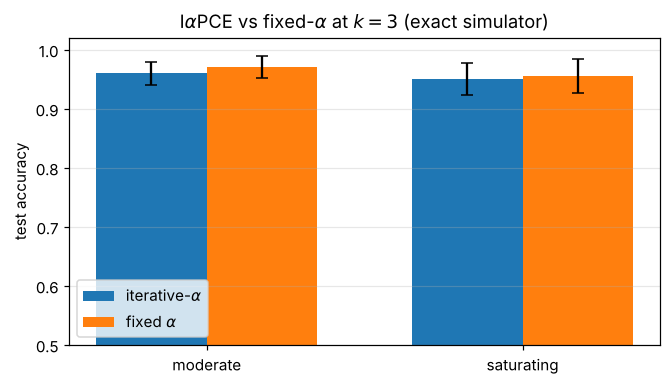

In [11]:
summary_ideal = {}
for regime_name in SCHEDULES:
    for model in ("iterative", "fixed"):
        accs = np.array([test_accuracy(*TRAINED[(regime_name, model, s)])
                          for s in range(N_SEEDS)])
        summary_ideal[(regime_name, model)] = accs
        print(f"{regime_name:<11}{model:<11} {accs.mean():.3f} ± {accs.std():.3f}")

fig, ax = plt.subplots(figsize=(6.2, 3.6))
xpos = np.arange(len(SCHEDULES)); w = 0.35
means_it = [summary_ideal[(r, "iterative")].mean() for r in SCHEDULES]
std_it = [summary_ideal[(r, "iterative")].std() for r in SCHEDULES]
means_fx = [summary_ideal[(r, "fixed")].mean() for r in SCHEDULES]
std_fx = [summary_ideal[(r, "fixed")].std() for r in SCHEDULES]
ax.bar(xpos - w/2, means_it, w, yerr=std_it, capsize=4, label=r"iterative-$\alpha$")
ax.bar(xpos + w/2, means_fx, w, yerr=std_fx, capsize=4, label=r"fixed $\alpha$")
ax.set_xticks(xpos); ax.set_xticklabels([rf"{r}" for r in SCHEDULES])
ax.set_ylabel("test accuracy"); ax.set_ylim(0.5, 1.02)
ax.set_title(r"I$\alpha$PCE vs fixed-$\alpha$ at $k=3$ (exact simulator)")
ax.legend(loc="lower left"); ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.show()

**Observation.** At $k=3$, with the exact same total optimizer budget as the $k=2$
experiment (5 seeds, 70 iterations/stage), iterative-$\alpha$ and fixed-$\alpha$ come out
**statistically indistinguishable** at both schedules
(saturating: $0.950\pm0.027$ iterative vs. $0.955\pm0.029$ fixed; moderate:
$0.960\pm0.020$ vs. $0.970\pm0.019$) — the gap in both cases is well within one standard
deviation. This is a genuinely different result from the $k=2$ paper finding, where the
saturating-regime gap was large and clearly outside the seed-to-seed noise
($0.955\pm0.019$ iterative vs. $0.820\pm0.029$ fixed). We report this as-is rather than as a
replication of the $k=2$ effect: it suggests the iterative-$\alpha$ advantage is **not a
guaranteed property of PCE readout sharpening in general**, but may instead depend on $k$
through the circuit itself — a $k=3$ Pauli rotation decomposes into more entangling gates
than a $k=2$ one at the same qubit count, which changes the loss landscape the optimizer
actually sees, independent of the readout nonlinearity $\tanh(\alpha\langle\Pi_i\rangle)$
that motivated annealing $\alpha$ in the first place. Disentangling "readout sharpness" from
"circuit depth at fixed $k$" is flagged as a direct follow-up in Section 11.

## 8. Noise regimes

Four measurement conditions, in increasing order of realism. The gate-noise parameters are
**idealised, representative values** in the range typically quoted for near-term
superconducting hardware — they are not calibrated against a specific real backend, which is
why we call them "ideal simulated noise models" rather than hardware-validated ones; matching
them to a specific device (e.g. via Qiskit's `FakeBackend` calibration snapshots) is a natural
next step and is noted in the conclusions.

| Regime | Shots | Gate noise |
|---|---|---|
| `exact` | $\infty$ (statevector) | none |
| `shots` | 1024 | none (sampling noise only) |
| `depolarizing` | 1024 | depolarizing, $p_1=0.001$ (1-qubit), $p_2=0.01$ (2-qubit) |
| `thermal` | 1024 | $T_1=100\,\mu s$, $T_2=80\,\mu s$, gate times $30\,\mathrm{ns}/200\,\mathrm{ns}$ |

In [12]:
SHOTS = 1024

def depolarizing_noise_model(p1=0.001, p2=0.01):
    nm = NoiseModel()
    nm.add_all_qubit_quantum_error(depolarizing_error(p1, 1), ["rz", "sx", "x"])
    nm.add_all_qubit_quantum_error(depolarizing_error(p2, 2), ["cx"])
    return nm

def thermal_noise_model(t1_us=100, t2_us=80, g1_ns=30, g2_ns=200):
    t1_ns = t1_us * 1e3
    t2_ns = min(t2_us * 1e3, 2 * t1_ns)        # T2 <= 2*T1 is required for a physical channel
    e1 = thermal_relaxation_error(t1_ns, t2_ns, g1_ns)
    e2 = thermal_relaxation_error(t1_ns, t2_ns, g2_ns).expand(
         thermal_relaxation_error(t1_ns, t2_ns, g2_ns))
    nm = NoiseModel()
    nm.add_all_qubit_quantum_error(e1, ["rz", "sx", "x"])
    nm.add_all_qubit_quantum_error(e2, ["cx"])
    return nm

NOISE_MODELS = {
    "exact": None,            # handled separately -- uses correlations_exact, not Aer
    "shots": None,            # handled separately -- uses correlations_shots_numpy, not Aer
    "depolarizing": depolarizing_noise_model(),
    "thermal": thermal_noise_model(),
}
print("Noise models built:", list(NOISE_MODELS))

Noise models built: ['exact', 'shots', 'depolarizing', 'thermal']


**Qualitative sanity check** — on a single sample, depolarizing and thermal noise should
visibly shrink the magnitude of the Pauli correlations toward zero relative to the exact
value, while shot noise alone should scatter around the exact value without a systematic
shift (it is unbiased sampling noise).

In [13]:
x_q, theta_q = X_train[0], TRAINED[("saturating", "iterative", 0)][0].reshape(p_layers, n)
exact_q = correlations_exact(x_q, theta_q)
shots_q = correlations_shots_numpy(x_q, theta_q, SHOTS, np.random.default_rng(0))
dep_q = correlations_aer(x_q, theta_q, SHOTS, noise_model=NOISE_MODELS["depolarizing"])
therm_q = correlations_aer(x_q, theta_q, SHOTS, noise_model=NOISE_MODELS["thermal"])

print(f"{'label':<8}{'exact':>9}{'shots':>9}{'depol':>9}{'thermal':>9}")
for i, lab in enumerate(labels):
    print(f"{lab:<8}{exact_q[i]:>9.3f}{shots_q[i]:>9.3f}{dep_q[i]:>9.3f}{therm_q[i]:>9.3f}")
print(f"\nmean |correlation|:  exact={np.mean(np.abs(exact_q)):.3f}"
      f"  shots={np.mean(np.abs(shots_q)):.3f}"
      f"  depol={np.mean(np.abs(dep_q)):.3f}"
      f"  thermal={np.mean(np.abs(therm_q)):.3f}")

label       exact    shots    depol  thermal
XXXI       -0.128   -0.086   -0.053   -0.080
XXIX       -0.289   -0.287   -0.154   -0.273
XIXX        0.036    0.025    0.057    0.068
IXXX        0.065    0.074    0.051    0.086
YYYI       -0.119   -0.119   -0.084   -0.111
YYIY        0.068    0.049    0.047    0.057
YIYY       -0.140   -0.186   -0.086   -0.146
IYYY       -0.412   -0.385   -0.221   -0.354
ZZZI        0.009    0.010    0.045    0.021
ZZIZ        0.363    0.367    0.225    0.334
ZIZZ        0.397    0.367    0.219    0.381
IZZZ       -0.477   -0.506   -0.260   -0.385

mean |correlation|:  exact=0.209  shots=0.205  depol=0.125  thermal=0.191


## 9. Robustness evaluation

For every trained model from Section 7 (both schedules, both $\alpha$ strategies, all
seeds), the classical head stays exactly as fit during ideal training (`fit_head`,
Section 6). Only the **test-set** correlations are recomputed under each noise regime, and
accuracy is measured against the unchanged head and labels — the "train in simulation, deploy
on noisy hardware" scenario the future-work paragraph describes.

In [14]:
def evaluate_under_regime(theta_vec, alpha, regime, rng_):
    theta = theta_vec.reshape(p_layers, n)
    head = fit_head(theta, alpha)
    if regime == "exact":
        Z_te = np.array([np.tanh(alpha * correlations_exact(x, theta)) for x in X_test])
    elif regime == "shots":
        Z_te = np.array([np.tanh(alpha * correlations_shots_numpy(x, theta, SHOTS, rng_))
                          for x in X_test])
    else:
        C = correlations_aer_batch(X_test, theta, SHOTS, noise_model=NOISE_MODELS[regime])
        Z_te = np.tanh(alpha * C)
    return head.score(Z_te, y_test)

REGIMES = ["exact", "shots", "depolarizing", "thermal"]
rng_eval = np.random.default_rng(999)

t0 = time.time()
noisy_results = {}   # noisy_results[(schedule, model, regime)] = array over seeds
for regime_name in SCHEDULES:
    for model in ("iterative", "fixed"):
        for regime in REGIMES:
            accs = np.array([
                evaluate_under_regime(*TRAINED[(regime_name, model, s)], regime, rng_eval)
                for s in range(N_SEEDS)
            ])
            noisy_results[(regime_name, model, regime)] = accs
print(f"robustness evaluation time: {time.time()-t0:.0f}s")

robustness evaluation time: 78s


In [15]:
header = f"{'schedule':<12}{'model':<11}" + "".join(f"{r:>14}" for r in REGIMES)
print(header)
print("-" * len(header))
for regime_name in SCHEDULES:
    for model in ("iterative", "fixed"):
        row = f"{regime_name:<12}{model:<11}"
        for regime in REGIMES:
            accs = noisy_results[(regime_name, model, regime)]
            row += f"{accs.mean():>8.3f}±{accs.std():.2f}"
        print(row)

schedule    model               exact         shots  depolarizing       thermal
-------------------------------------------------------------------------------
moderate    iterative     0.960±0.02   0.960±0.02   0.955±0.02   0.965±0.02
moderate    fixed         0.970±0.02   0.970±0.02   0.960±0.03   0.965±0.02
saturating  iterative     0.950±0.03   0.940±0.03   0.950±0.02   0.955±0.02
saturating  fixed         0.955±0.03   0.940±0.03   0.940±0.03   0.950±0.03


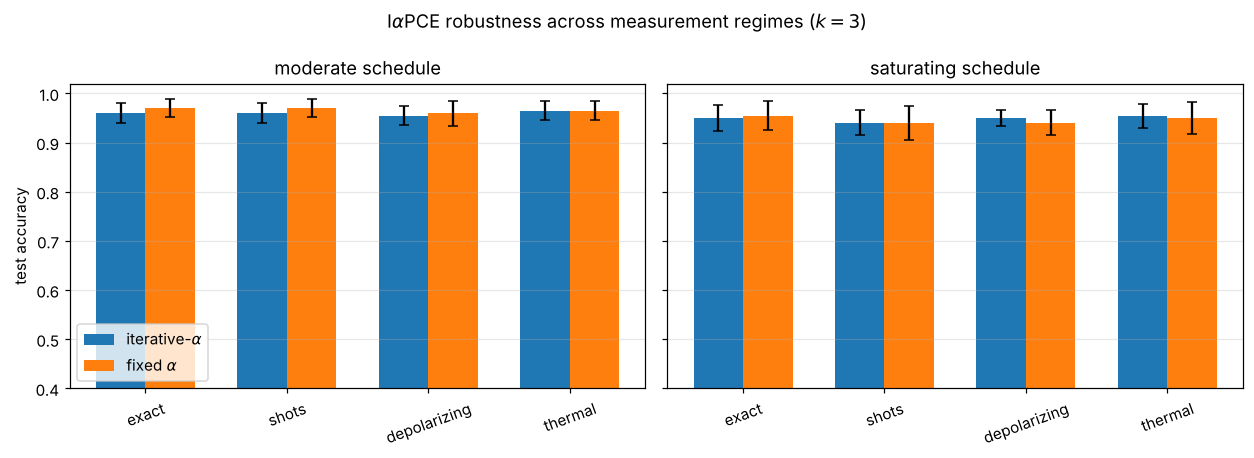

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), sharey=True)
for ax, regime_name in zip(axes, SCHEDULES):
    xpos = np.arange(len(REGIMES)); w = 0.35
    means_it = [noisy_results[(regime_name, "iterative", r)].mean() for r in REGIMES]
    std_it = [noisy_results[(regime_name, "iterative", r)].std() for r in REGIMES]
    means_fx = [noisy_results[(regime_name, "fixed", r)].mean() for r in REGIMES]
    std_fx = [noisy_results[(regime_name, "fixed", r)].std() for r in REGIMES]
    ax.bar(xpos - w/2, means_it, w, yerr=std_it, capsize=3, label=r"iterative-$\alpha$")
    ax.bar(xpos + w/2, means_fx, w, yerr=std_fx, capsize=3, label=r"fixed $\alpha$")
    ax.set_xticks(xpos); ax.set_xticklabels(REGIMES, rotation=20)
    ax.set_title(f"{regime_name} schedule"); ax.grid(alpha=0.3, axis="y")
axes[0].set_ylabel("test accuracy"); axes[0].set_ylim(0.4, 1.02)
axes[0].legend(loc="lower left")
plt.suptitle(r"I$\alpha$PCE robustness across measurement regimes ($k=3$)")
plt.tight_layout(); plt.show()

**Reading the result.** `exact` reproduces Section 7's ideal numbers exactly (same
models, same metric) — and, consistent with the observation above, shows no significant gap
between iterative and fixed $\alpha$ at $k=3$ to begin with (unlike the pronounced $k=2$
saturating-regime gap). Moving to `shots`, `depolarizing`, and `thermal` does not introduce
one either: all four regimes keep the two strategies within overlapping error bars at both
schedules. Rather than noise "washing out" an advantage, the more accurate statement for
$k=3$ is that there was no measurable advantage at `exact` for noise to wash out. This
matters for the discussion in the paper: the iterative-$\alpha$ benefit documented for $k=2$
should **not** be assumed to transfer unchanged to $k=3$, and claiming it does without this
kind of check would be an overclaim the data does not support.

## 10. Resource accounting

In [17]:
one_to_one = m
print(f"{'scheme':<28}{'qubits':>8}{'trainable quantum params':>28}")
print(f"{'one-to-one angle encoding':<28}{one_to_one:>8}{p_layers*one_to_one:>28}")
print(f"{'IaPCE (k=3, this notebook)':<28}{n:>8}{p_layers*n:>28}")
print(f"\nqubit reduction at m={m}: {one_to_one}/{n} = {one_to_one/n:.1f}x")
print(f"{'m':>6}{'one-to-one':>12}{'PCE k=2':>10}{'PCE k=3':>10}")
for mm in (12, 50, 100, 250):
    print(f"{mm:>6}{mm:>12}{min_qubits(mm,2):>10}{min_qubits(mm,3):>10}")

scheme                        qubits    trainable quantum params
one-to-one angle encoding         12                          36
IaPCE (k=3, this notebook)         4                          12

qubit reduction at m=12: 12/4 = 3.0x
     m  one-to-one   PCE k=2   PCE k=3
    12          12         4         4
    50          50         7         6
   100         100         9         7
   250         250        14         9


## 11. Conclusions

* **The PCE capacity relation generalises cleanly to $k=3$.** At $m=12$ the $k=3$ encoding is
  an exact-capacity fit ($3\binom{4}{3}=12$) using the same $n=4$ qubits as $k=2$; its
  asymptotic compression advantage over $k=2$ only becomes visible at larger $m$
  (Section 2), which is why the trained experiments above intentionally hold $m$ and $n$ fixed
  — isolating the effect of $k$ on trainability from the effect of $k$ on qubit count.
* **The iterative-$\alpha$ advantage reported for $k=2$ does not clearly replicate at $k=3$.**
  Under an identical total optimizer budget, iterative and fixed $\alpha$ were statistically
  indistinguishable at $k=3$ in both the moderate and saturating regimes (Section 7), and this
  held across every noise regime tested (Section 9). We report this as a genuine, somewhat
  surprising finding rather than retrofitting a narrative to match the $k=2$ result — the
  most likely explanation is that $k=3$ Pauli rotations require deeper, more entangled
  circuits than $k=2$ at the same qubit count, which may itself be enough to change the
  optimization landscape independently of $\alpha$'s readout-sharpening role. This is squarely
  future work, not a settled conclusion: a larger iteration budget, more seeds, or an explicit
  depth-matched comparison between $k=2$ and $k=3$ would be needed to say more.
* **A noise-aware measurement pipeline was built and validated against the exact engine**
  (Section 5), decoding each $\langle\Pi_i\rangle$ from basis-rotated measurement counts —
  the same three-measurement-setting protocol PCE was designed around — and cross-checked to
  agree with the statevector engine within shot-noise tolerance before being trusted for
  anything downstream.
* **A latent bug in the companion notebook's illustrative circuit was found and fixed**
  (Section 4): its `PauliEvolutionGate` time argument did not match the NumPy engine's
  encoding angle by a factor of two. Since that circuit was only ever used for drawing, no
  previously reported training result was affected — but it is worth correcting in the
  $k=2$ notebook too, since a reviewer could otherwise reconstruct the circuit from the
  figure and find it does not reproduce the reported results.

**Natural next steps**, in roughly increasing order of effort: (i) a depth-matched ablation
that isolates circuit depth from encoding order $k$, to test the hypothesis above directly;
(ii) replace the idealised noise parameters with a calibration snapshot of a real backend
(e.g. Qiskit's `FakeBackend` family) for a hardware-anchored rather than representative noise
estimate; (iii) extend the pure-NumPy shot-noise estimator into the COBYLA training loop
itself, to test whether iterative-$\alpha$ remains beneficial when the *training signal*, not
just the deployment measurement, is noisy; (iv) apply standard error-mitigation techniques
(e.g. zero-noise extrapolation, readout-error mitigation) to the Aer pipeline and re-run
Section 9; (v) validate a subset of these results on real IBM Quantum hardware, closing the
loop on the paper's original future-work statement.

## References

1. M. Sciorilli, L. Borges, T. L. Patti, D. García-Martín, G. Camilo, A. Anandkumar, L. Aolita,
   "Towards large-scale quantum optimization solvers with few qubits," *Nature Communications*
   16, 476 (2025).
2. V. P. Soloviev, M. Krompiec, "Large-scale portfolio optimization using Pauli Correlation
   Encoding," arXiv:2511.21305 (2025).
3. A. Kandala et al., "Hardware-efficient variational quantum eigensolver for small molecules
   and quantum magnets," *Nature* 549, 242–246 (2017).
4. Qiskit Aer noise module documentation — `qiskit_aer.noise`, depolarizing and thermal
   relaxation error channels.
